In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv('orders_clean.csv')
df.head(10)

,order_id,customer_id,order_date,category,quantity,unit_price,discount,returned,net_revenue
0,4913,1116,2026-09-17,Tech,2,115.41,0.2,True,0.00
1,2130,96,2026-07-25,Clothing,4,148.20,0.1,False,533.52
2,3816,430,2026-09-12,Home,4,109.99,0.2,False,351.97
3,2894,329,2026-08-30,Tech,3,101.31,0.1,False,273.54
4,446,24,2026-08-17,Tech,4,64.66,0.2,False,206.91
5,1990,31,2026-09-11,Home,4,45.90,0.0,False,183.60
6,1137,767,2026-09-23,Clothing,2,34.37,0.1,False,61.87
7,1678,1199,2026-09-30,Tech,3,98.41,0.0,False,295.23
8,1515,887,2026-09-20,Home,2,70.47,0.0,False,140.94
9,1410,870,2026-08-03,Tech,4,18.49,0.2,False,59.17


In [8]:
df["order_date"] = pd.to_datetime(df["order_date"])

df["returned"] = (
    df["returned"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"true":True,"false":False})
)

assert df["returned"].notna().all()
assert df["order_id"].is_unique

df.head(10)

,order_id,customer_id,order_date,category,quantity,unit_price,discount,returned,net_revenue
0,4913,1116,2026-09-17,Tech,2,115.41,0.2,True,0.00
1,2130,96,2026-07-25,Clothing,4,148.20,0.1,False,533.52
2,3816,430,2026-09-12,Home,4,109.99,0.2,False,351.97
3,2894,329,2026-08-30,Tech,3,101.31,0.1,False,273.54
4,446,24,2026-08-17,Tech,4,64.66,0.2,False,206.91
5,1990,31,2026-09-11,Home,4,45.90,0.0,False,183.60
6,1137,767,2026-09-23,Clothing,2,34.37,0.1,False,61.87
7,1678,1199,2026-09-30,Tech,3,98.41,0.0,False,295.23
8,1515,887,2026-09-20,Home,2,70.47,0.0,False,140.94
9,1410,870,2026-08-03,Tech,4,18.49,0.2,False,59.17


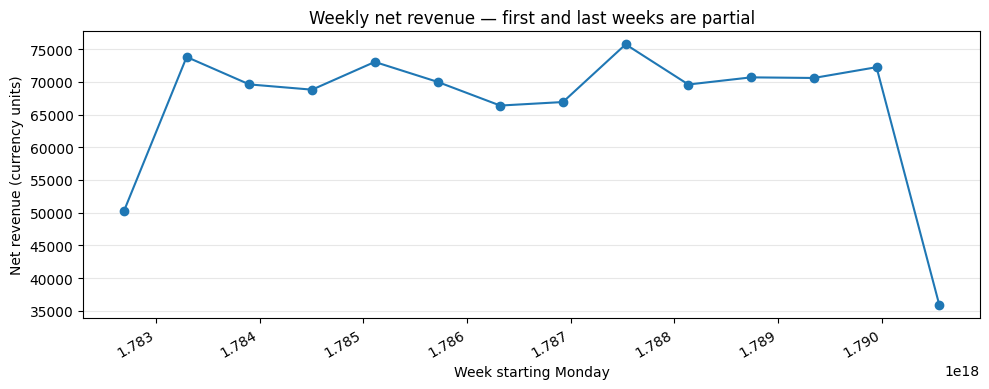

In [9]:
df["week_start"] = (
    df["order_date"]
    - pd.to_datetime(df["order_date"].dt.dayofweek, unit="D")
)

weekly = (
    df.groupby("week_start")["net_revenue"]
    .sum()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(weekly.index, weekly.values, marker="o")
ax.set(
    title="Weekly net revenue — first and last weeks are partial",
    xlabel="Week starting Monday",
    ylabel="Net revenue (currency units)"
)
ax.grid(axis="y", alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

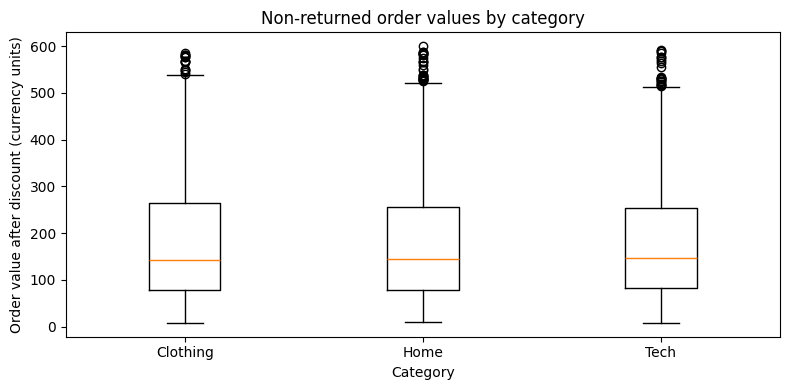

In [10]:
non_returned = df.loc[~df["returned"]].copy()

categories = sorted(non_returned["category"].unique())

category_values = [
    non_returned.loc[
        non_returned["category"].eq(category), "net_revenue"
    ].to_numpy()
    for category in categories
]

fig, ax = plt.subplots(figsize=(8, 4))

ax.boxplot(category_values)
ax.set_xticks(range(1, len(categories) + 1))
ax.set_xticklabels(categories)
ax.set(
    title="Non-returned order values by category",
    xlabel="Category",
    ylabel="Order value after discount (currency units)"
)

plt.tight_layout()
plt.show()

In [11]:
values = non_returned["net_revenue"].to_numpy()

q1, median, q3, p90 = np.percentile(values, [25, 50, 75, 90])

print(f"Median: {median:.2f}")
print(f"90th percentile: {p90:.2f}")
print(f"Interquartile range: {q3 - q1:.2f}")

Median: 144.58
90th percentile: 374.40
Interquartile range: 177.26


          total_orders  returned_orders  net_revenue  return_rate
category                                                         
Clothing          1884              240    299855.78        0.127
Home              1911              210    307854.94        0.110
Tech              2060              250    325755.65        0.121


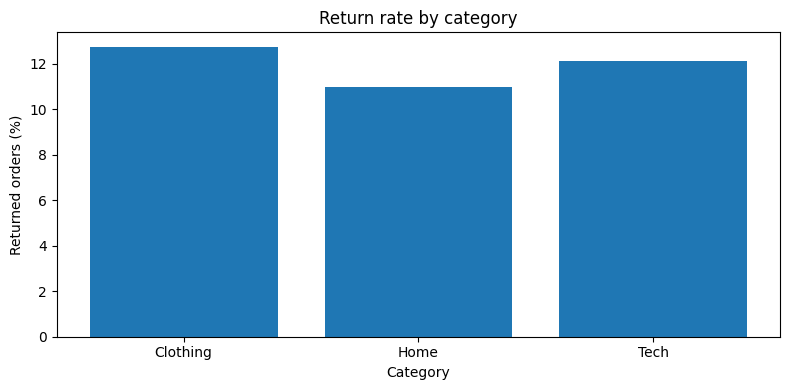

In [12]:
category_summary = df.groupby("category").agg(
    total_orders=("order_id", "count"),
    returned_orders=("returned", "sum"),
    net_revenue=("net_revenue", "sum")
)

category_summary["return_rate"] = (
    category_summary["returned_orders"]
    / category_summary["total_orders"]
)

print(category_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    category_summary.index,
    category_summary["return_rate"] * 100
)
ax.set(
    title="Return rate by category",
    xlabel="Category",
    ylabel="Returned orders (%)"
)

plt.tight_layout()
plt.show()